# House Prices Dataset
[kaggle](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques/data)

In [9]:
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from ipywidgets import interact
from IPython.display import Markdown
%matplotlib inline

In [2]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

path = kagglehub.competition_download('house-prices-advanced-regression-techniques')

In [3]:
df = pd.read_csv(path + '/train.csv')
df_test = pd.read_csv(path + '/test.csv')

# Hipoteza 1: Domy z większym parkingiem sprzedają się drożej

In [15]:
print(f'Min: {df['LotArea'].min()} [ft^2]\nMax: {df['LotArea'].max()} [ft^2]')

Min: 1300 [ft^2]
Max: 215245 [ft^2]


In [16]:
print('Correlation:', df['LotArea'].corr(df['SalePrice']))

Correlation: 0.2638433538714056


In [27]:
x = [df['LotArea'].quantile(x) for x in np.linspace(0, 1, 10)]
x_pairs = [(x[i], x[i + 1]) for i in range(len(x) - 1)]

by_cls = pd.DataFrame([
    {
        'MinLotArea': round(x_min),
        'MaxLotArea': round(x_max),
        'Average House Price (k$)': round((row := df.loc[(df['LotArea'] >= x_min) & (df['LotArea'] < x_max), 'SalePrice']).mean() // 1000),
        'Standard Devaition of House Price': round(row.std()),
        '5rd Min House Price (k$)': round(row.nsmallest(5).iloc[-1] // 1000),
        '5rd Max House Price (k$)': round(row.nlargest(5).iloc[-1] // 1000),
    }
    for x_min, x_max in x_pairs
])

display(Markdown('## Average price by lot area range'))
by_cls

## Average price by lot area range

,MinLotArea,MaxLotArea,Average House Price (k$),Standard Devaition of House Price,5rd Min House Price (k$),5rd Max House Price (k$)
0,1300,5382,146,48908,73,251
1,5382,7200,132,46998,68,236
2,7200,8400,152,47002,68,263
3,8400,9063,156,54792,67,270
4,9063,9837,175,57648,87,315
5,9837,10766,185,67114,95,341
6,10766,11948,198,71325,90,369
7,11948,14115,227,97072,104,451
8,14115,215245,249,112274,113,555


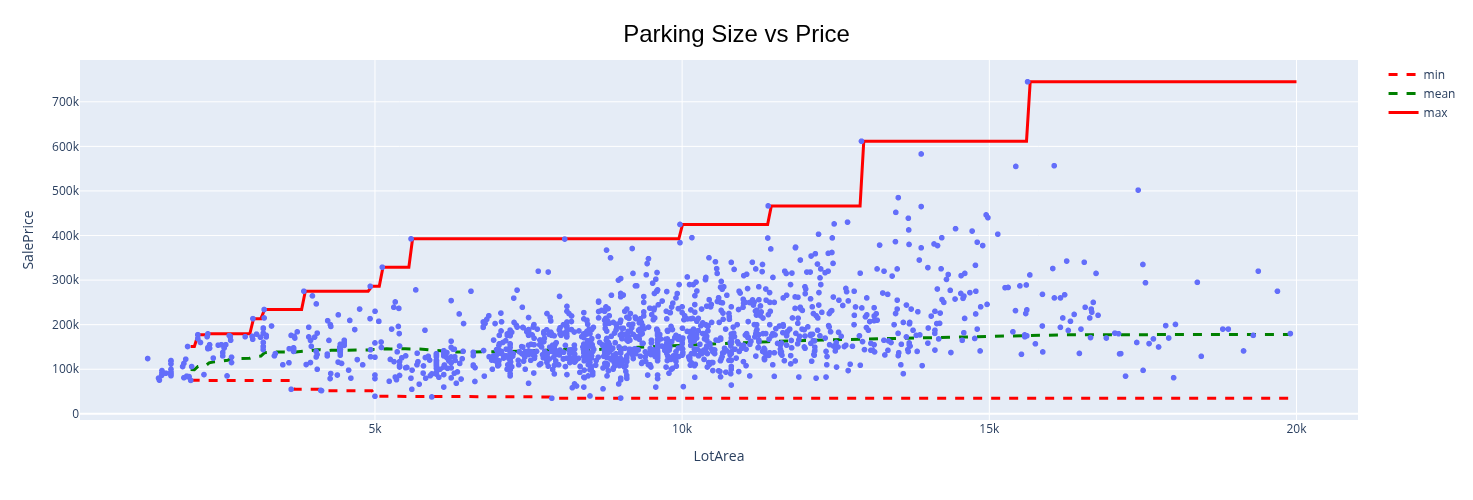

In [31]:
data = df[df['LotArea'] < 20_000]
fig = px.scatter(data, x='LotArea', y='SalePrice', width=900, height=500, title='')
fig.update_layout(title=dict(
    text="Parking Size vs Price",
    x=0.5, xanchor="center", y=0.95,
    font=dict(
        size=24,
        family="Arial",
        color="black"
    )
))
x = np.linspace(2_000, 20_000, 300)
fig.add_trace(go.Scatter(x=x, y=[data[data['LotArea'] < end]['SalePrice'].min() for end in x], name='min', line=dict(color="red", width=3, dash='dash')))
fig.add_trace(go.Scatter(x=x, y=[data[data['LotArea'] < end]['SalePrice'].mean() for end in x], name='mean', line=dict(color="green", width=3, dash='dash')))
fig.add_trace(go.Scatter(x=x, y=[data[data['LotArea'] < end]['SalePrice'].max() for end in x], name='max', line=dict(color="red", width=3)))

In [32]:
df[df['LotArea'] < 10000]['LotArea'].corr(df['SalePrice'])

np.float64(0.2131717337385616)

<br/>

## Hipoteza 1 **nie** jest niepodważalnie prawdziwa,
lecz można zauważyć że aby dom był warty **bardzo dużo (>470k$)** warunkiem koniecznym jest aby miał parking **przynajmniej 12k - 16k** (w danych treningowych).
<br/><br/>

# Siatka korelaci kolumn liczbowych

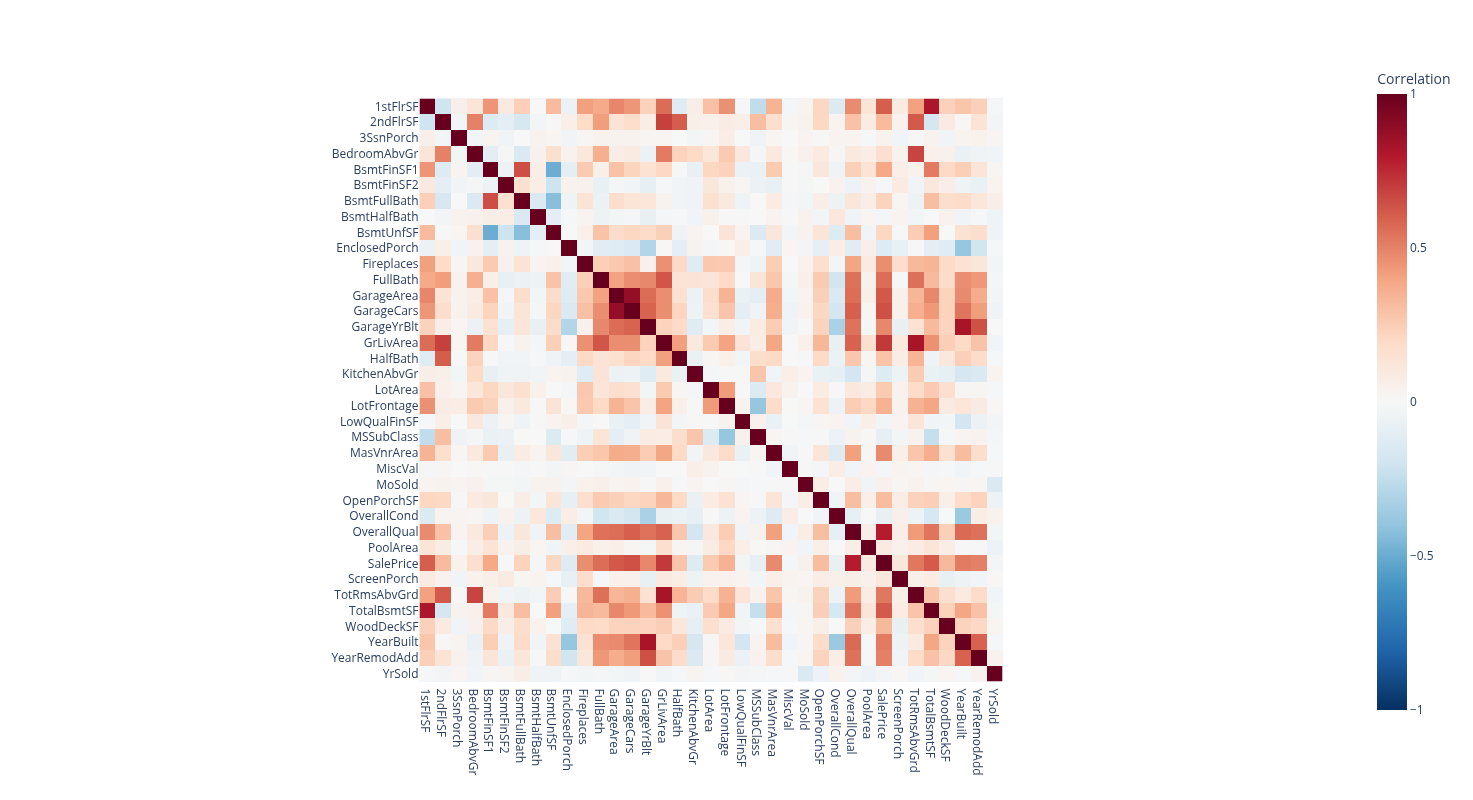

In [33]:
numeric_columns = sorted(list({col for col in df.columns if df[col].dtype.kind in ('i', 'f')} - {'Id'}))

corr = df[numeric_columns].corr()

fig = px.imshow(corr, zmin=-1, zmax=1, labels=dict(color='Correlation'), color_continuous_scale='RdBu_r')
fig.update_layout(width=800, height=800)

## Korelacje w danych
`OverallQual` rośnie podobnie do `SalePrice`.<br>
`YearBuilt` rośnie podobnie do `GarageYrBlt`.<br>
`GarageCars` rośnie podobnie do `GarageArea`.<br>
`GrLivArea` (Above grade (ground) living area square feet) rośnie podobnie do `FullBath` (Full bathrooms above grade).<br>

`MiscVal` ($Value of miscellaneous feature), `MoSold` (Month Sold) i `YrSold` (Year Sold) nie korelują z żadnymi innymi wartościami numerycznymi.<br>

# Hipoteza 2: Im młodszy budynek tym lepsza jest jego całościowa jakość

In [47]:
def plot_with_counts(df, x_col, y_col, labels={}, max_size=22):
    counts = (
        df.groupby([x_col, y_col])
          .size()
          .reset_index(name="count")
    )
    
    return px.scatter(counts, x=x_col, y=y_col, size='count', size_max=max_size, width=1400, height=700, labels=labels)

def round_col(df, col, nb):
    return df.assign(**{col: (df[col] // nb) * nb})

### Korelacja roku wybudowania z jakością budynku: 0.572<br>

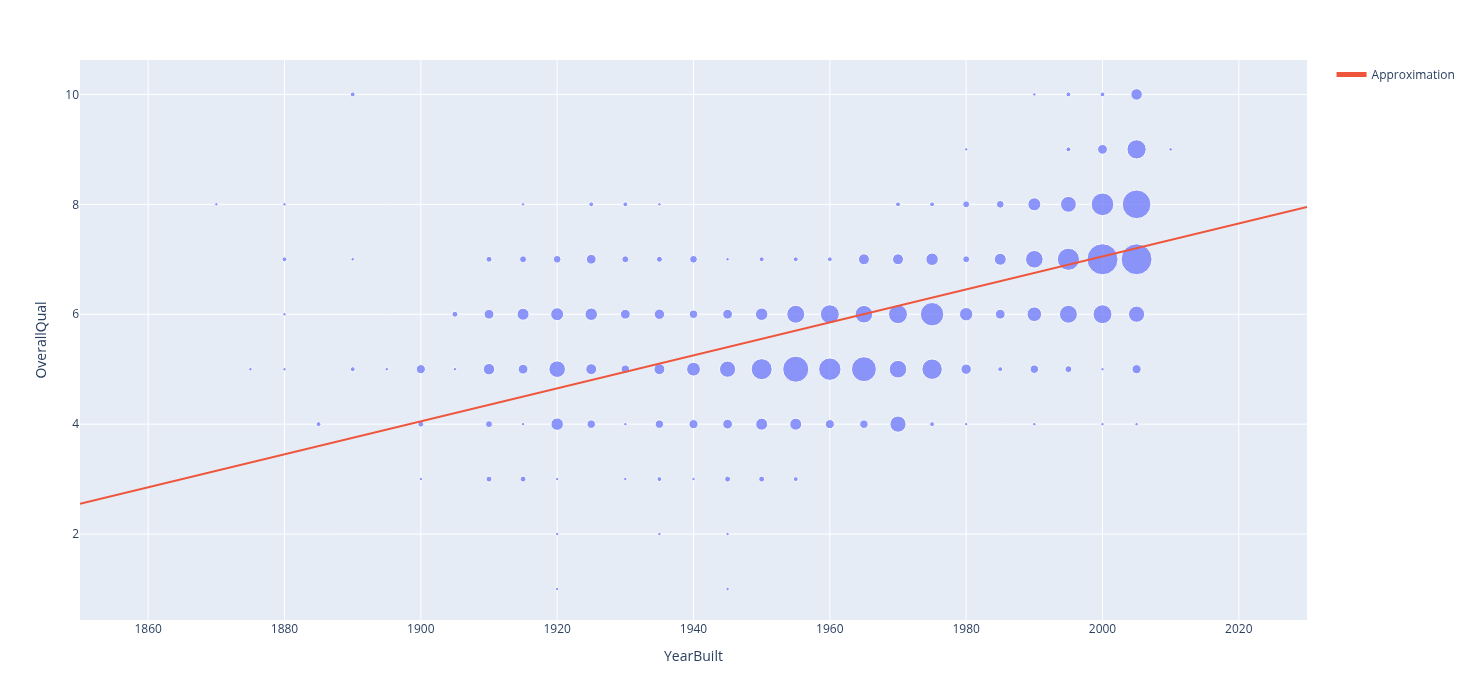

In [48]:
display(Markdown(f'### Korelacja roku wybudowania z jakością budynku: {df['YearBuilt'].corr(df['OverallQual']):.3f}<br>'))

fig = plot_with_counts(round_col(df, 'YearBuilt', 5), 'YearBuilt', 'OverallQual')
x = np.linspace(1850, 2030, 50)
fig.add_trace(go.Scatter(x=x, y=3/100 * (x - 1765), name='Approximation'))
fig

## Hipoteza 2 jest prawdziwa, jakość budynków ulegała lekkiej poprawie od ~1880 roku do ~2010 roku